# scShapeBench Tutorial

This notebook demonstrates how to download and analyze datasets from scShapeBench 

## Imports

In [10]:
import math
import sys
from collections import deque
from pathlib import Path

from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
import numpy as np
from sklearn.decomposition import PCA
import anndata as ad
from huggingface_hub import hf_hub_download
from huggingface_hub import hf_hub_download
import anndata as ad
import json
import pandas as pd
import networkx as nx
import phate

# Make the local repo importable before the package is published.
repo_root = Path.cwd()
if not (repo_root / "src").exists() and (repo_root.parent / "src").exists():
    repo_root = repo_root.parent
sys.path.insert(0, str(repo_root / "src"))

from sc_reeb_tower import scReebTower, plot_scReebTower, extract_cellular_trajectory, enumerate_terminal_cellular_trajectories

#dataset numbers to import
sc1_ds = "SCD-0002"
sc2_ds = "SCD-0074"

syn1_ds = "sample_00000"
syn2_ds = "sample_00500"

## Helpers

In [2]:
def project_pca_2d(X):
    return PCA(n_components=2, random_state=0).fit_transform(X)


def scReebTower_with_plotting(X, **kwargs):
    options = dict(
        return_raw=True,
        return_intermediates=True,
        return_simp_persistence=True,
    )
    options.update(kwargs)
    return scReebTower(X, **options)


def summarize_result(result, title=None):
    simp = result["simplified"]
    persistence = simp.get("persistence", {})
    if title:
        print(title)
        print("-" * len(title))
    print("nodes:", len(simp["nodes"]))
    print("edges:", len(simp["edges"]))
    print("beta1:", simp["beta1"])
    print("components:", simp["comp_count"])
    if "h1" in persistence:
        print("H1 count:", persistence["h1"].shape[0])
    print("selected diffusion eigenvalues:", result["intermediates"].get("diffusion_eigenvalues"))


def plot_filter_values(X, filter_values, title, elev=20, azim=-55):
    X = np.asarray(X)
    fig = plt.figure(figsize=(7, 6))
    if X.shape[1] == 3:
        ax = fig.add_subplot(111, projection="3d")
        sc = ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=filter_values, cmap="viridis", s=8, alpha=0.85)
        ax.view_init(elev=elev, azim=azim)
        ax.set_box_aspect(np.ptp(X, axis=0) + 1e-12)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_zlabel("z")
    else:
        ax = fig.add_subplot(111)
        sc = ax.scatter(X[:, 0], X[:, 1], c=filter_values, cmap="viridis", s=8, alpha=0.85)
        ax.set_xlabel("dim 1")
        ax.set_ylabel("dim 2")
        ax.set_aspect("equal", adjustable="box")
    ax.set_title(title)
    fig.colorbar(sc, ax=ax, shrink=0.8, pad=0.08, label="filter value")
    plt.show()


def plot_persistence_diagram(persistence, title="Persistence Diagram"):
    fig, ax = plt.subplots(figsize=(5.5, 5.5))

    finite_vals = []
    for key in ("h0", "h1"):
        arr = persistence[key]
        if arr.size > 0:
            finite_vals.extend(arr[np.isfinite(arr)].ravel().tolist())

    max_finite = max(finite_vals) if finite_vals else 1.0
    inf_y = max_finite * 1.1 + 1e-6

    h0 = persistence["h0"]
    if h0.size > 0:
        ax.scatter(h0[:, 0], h0[:, 1], color="tab:blue", s=40, label="H0")

    h1 = persistence["h1"]
    if h1.size > 0:
        y = np.where(np.isfinite(h1[:, 1]), h1[:, 1], inf_y)
        ax.scatter(h1[:, 0], y, color="crimson", marker="x", s=55, label="H1")

    h0e = persistence["h0_essential"]
    if h0e.size > 0:
        y = np.where(np.isfinite(h0e[:, 1]), h0e[:, 1], inf_y)
        ax.scatter(h0e[:, 0], y, color="tab:green", marker="^", s=48, label="H0 essential")

    lo = 0.0
    hi = max(max_finite, inf_y)
    ax.plot([lo, hi], [lo, hi], linestyle="--", color="gray", linewidth=1.0)
    ax.axhline(inf_y, linestyle=":", color="gray", linewidth=1.0)
    ax.text(lo, inf_y, "inf", va="bottom", ha="left", fontsize=9)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, inf_y * 1.02)
    ax.set_title(title)
    ax.set_xlabel("Birth")
    ax.set_ylabel("Death")
    ax.legend()
    ax.set_aspect("equal", adjustable="box")
    plt.show()


def plot_overlay(result, pts, title, label_degree=True, elev=None, azim=None):
    fig, _ = plot_scReebTower(
        pts=pts,
        simp_edges=result["simplified"]["edges"],
        keep_ids=result["simplified"]["keep_ids"],
        reeb_nodes=result["raw"]["nodes"],
        step_vertices=result["intermediates"]["step_vertices"],
        step_comp_ids=result["intermediates"]["step_comp_ids"],
        uniq_v=result["intermediates"]["prep_state"]["uniq_v"],
        color_cycles=True,
        label_degree=label_degree,
        figsize=(8, 7),
    )
    if fig.axes:
        ax = fig.axes[0]
        ax.set_title(title)
        # Only meaningful for 3D axes; silently skipped for 2D overlays.
        if hasattr(ax, "view_init") and (elev is not None or azim is not None):
            ax.view_init(
                elev=elev if elev is not None else 20,
                azim=azim if azim is not None else -58,
            )
    plt.show()


def simplified_degrees(num_nodes, edges):
    deg = np.zeros(num_nodes, dtype=int)
    for u, v in edges:
        deg[int(u)] += 1
        deg[int(v)] += 1
    return deg


def build_simple_adjacency(num_nodes, edges):
    adj = [[] for _ in range(num_nodes)]
    for eid, (u, v) in enumerate(edges):
        u = int(u)
        v = int(v)
        adj[u].append((v, eid))
        if u != v:
            adj[v].append((u, eid))
    return adj


def edge_path_between_nodes(num_nodes, edges, start, goal):
    adj = build_simple_adjacency(num_nodes, edges)
    parent = {int(start): None}
    parent_edge = {}
    q = deque([int(start)])
    while q:
        u = q.popleft()
        if u == int(goal):
            break
        for v, eid in adj[u]:
            if v not in parent:
                parent[v] = u
                parent_edge[v] = eid
                q.append(v)
    if int(goal) not in parent:
        return []
    path_edges = []
    cur = int(goal)
    while parent[cur] is not None:
        path_edges.append(parent_edge[cur])
        cur = parent[cur]
    path_edges.reverse()
    return path_edges


def highlight_points(pts, selected, title, selected_color="crimson", base_alpha=0.18):
    pts = np.asarray(pts)
    selected = np.asarray(selected, dtype=int)
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.scatter(pts[:, 0], pts[:, 1], s=8, color="lightgray", alpha=base_alpha)
    if selected.size > 0:
        ax.scatter(pts[selected, 0], pts[selected, 1], s=12, color=selected_color, alpha=0.9)
    ax.set_title(title)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("dim 1")
    ax.set_ylabel("dim 2")
    plt.show()

def build_graph(nodes, edges, title):
    fig, ax = plt.subplots(figsize=(4, 4))
    G = nx.Graph()
    G.add_nodes_from(nodes)
    G.add_edges_from(edges)
    pos = nx.kamada_kawai_layout(G)
    nx.draw_networkx_edges(G, pos, edge_color='#888888', width=1.2, ax=ax)
    nx.draw_networkx_nodes(
    G, pos,
    node_color='white', 
    edgecolors="#000000",   
    node_size=50,
    linewidths=0.5,
    ax=ax
)
    ax.set_title(title)
    ax.axis('off')
    plt.show()

def plot_clean_noisy(syn, elev=20, azim=-55):
    if syn["clean_points"].shape[1] == 3:
        fig = plt.figure(figsize=(16, 8))
        
        ax0 = fig.add_subplot(121, projection="3d")
        ax0.scatter(syn["clean_points"][:, 0], syn["clean_points"][:, 1], syn["clean_points"][:, 2], 
                    color="tab:blue", s=8, alpha=0.85)
        ax0.view_init(elev=elev, azim=azim)
        ax0.set_box_aspect(np.ptp(syn["clean_points"], axis=0) + 1e-12)
        ax0.set_xlabel("x"); ax0.set_ylabel("y"); ax0.set_zlabel("z")
        ax0.set_title("Clean Points")

        ax1 = fig.add_subplot(122, projection="3d")
        ax1.scatter(syn["noisy_points"][:, 0], syn["noisy_points"][:, 1], syn["noisy_points"][:, 2], 
                    color="tab:orange", s=8, alpha=0.85)
        ax1.view_init(elev=elev, azim=azim)
        ax1.set_box_aspect(np.ptp(syn["noisy_points"], axis=0) + 1e-12)
        ax1.set_xlabel("x"); ax1.set_ylabel("y"); ax1.set_zlabel("z")
        ax1.set_title("Noisy Points")

    else:
        fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(8, 4))  
        
        ax0.scatter(syn["clean_points"][:, 0], syn["clean_points"][:, 1], 
                    color="tab:blue", s=8, alpha=0.85)  
        ax0.set_xlabel("x"); ax0.set_ylabel("y")
        ax0.set_aspect("equal", adjustable="box")
        ax0.set_title("Clean Points")

        ax1.scatter(syn["noisy_points"][:, 0], syn["noisy_points"][:, 1], 
                    color="tab:orange", s=8, alpha=0.85)
        ax1.set_xlabel("x"); ax1.set_ylabel("y")
        ax1.set_aspect("equal", adjustable="box")
        ax1.set_title("Noisy Points")

    plt.tight_layout()
    plt.show()
    
def print_metadata(meta, title=None):
    if title:
        print(title)
        print("-" * len(title))
    gs = meta.get("graph_summary", {})
    dc = meta.get("difficulty_coordinate", {})
    print(f"sample_id:              {meta.get('sample_id')}")
    print(f"difficulty:             {meta.get('difficulty')}")
    print(f"topology_class:         {meta.get('topology_class')}")
    print(f"embedding_dimension:    {meta.get('embedding_dimension')}")
    print(f"num_components:         {meta.get('num_components')}")
    print(f"H1 cycles:              {meta.get('betti_1')}")
    print(f"leaf_count:             {meta.get('leaf_count')}")
    print(f"num_nodes:              {gs.get('num_nodes')}")
    print(f"num_edges:              {gs.get('num_edges')}")
    print(f"num_clean_points:       {meta.get('num_clean_points')}")
    print(f"tube_sampling_mode:     {meta.get('tube_sampling_mode')}")
    print(f"noise_ratio:            {dc.get('noise_ratio', meta.get('realized_noise_ratio')):.4f}")
    print(f"crowding_r:             {dc.get('crowding_r', meta.get('realized_crowding_r')):.4f}")
    print(f"sampling_density:       {dc.get('sampling_density_per_feature'):.2f}")
    print(f"feature_thickness:      {dc.get('feature_thickness_ratio', meta.get('feature_thickness_ratio')):.4f}")

### Downloading the Entire Dataset (100+ GB)

In [ ]:
from huggingface_hub import snapshot_download

DOWNLOAD = False
if DOWNLOAD:
    # change this to the directory you want to download the dataset to
    directory = "./scShapeBench"
    snapshot_download(repo_id="scShape-Benchmark/scShapeBench", repo_type="dataset", local_dir=directory)

## Synthetic Data Imports

In [12]:
syn1_path = hf_hub_download(repo_id="scShape-Benchmark/scShapeBench", repo_type="dataset", filename=f"data/synthetic/{syn1_ds}.npz")
syn1_meta_path = hf_hub_download(repo_id="scShape-Benchmark/scShapeBench", repo_type="dataset", filename=f"data/synthetic/{syn1_ds}.json")

syn2_path = hf_hub_download(repo_id="scShape-Benchmark/scShapeBench", repo_type="dataset", filename=f"data/synthetic/{syn2_ds}.npz")
syn2_meta_path = hf_hub_download(repo_id="scShape-Benchmark/scShapeBench", repo_type="dataset", filename=f"data/synthetic/{syn2_ds}.json")

syn1 = np.load(syn1_path)
syn2 = np.load(syn2_path)

syn1_meta = json.load(open(syn1_meta_path))
syn2_meta = json.load(open(syn2_meta_path))

In [13]:
syn1.files

['nodes', 'edges', 'positions', 'clean_points', 'noisy_points']

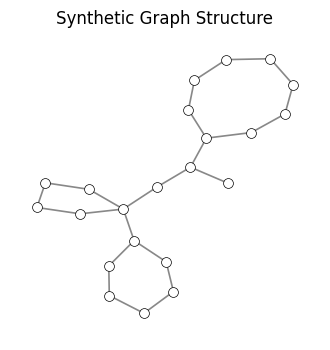

In [14]:
build_graph(syn1["nodes"], syn1["edges"], title="Synthetic Graph Structure")

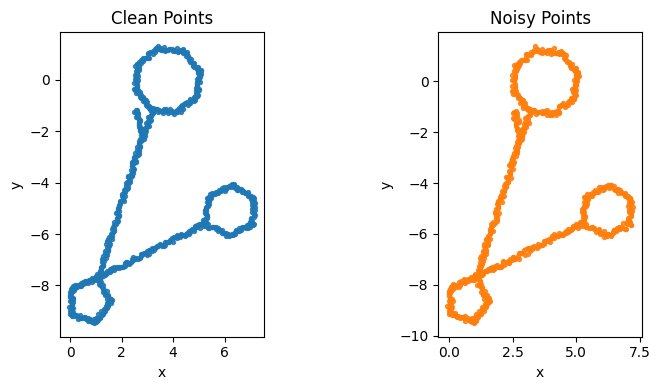

In [23]:
plot_clean_noisy(syn1)

In [24]:
syn1_result = scReebTower_with_plotting(
    syn1['noisy_points'],
    k=30,
    diffusion_eigen_index=1,
    return_point_assignment=True,
    return_edge_assignment=True,
    return_cellular_decomposition=True,
)

summarize_result(syn1_result, title="Synthetic point cloud with point and edge assignments")

Synthetic point cloud with point and edge assignments
-----------------------------------------------------
nodes: 10
edges: 12
beta1: 3
components: 1
H1 count: 3
selected diffusion eigenvalues: [0.99903707]


In [25]:
print_metadata(syn1_meta, title="Synthetic dataset metadata")

Synthetic dataset metadata
--------------------------
sample_id:              10
difficulty:             full
topology_class:         branchy_cycle
embedding_dimension:    3
num_components:         1
H1 cycles:              2
leaf_count:             17
num_nodes:              61
num_edges:              62
num_clean_points:       1553
tube_sampling_mode:     solid
noise_ratio:            0.0312
crowding_r:             0.0156
sampling_density:       22.30
feature_thickness:      0.6718


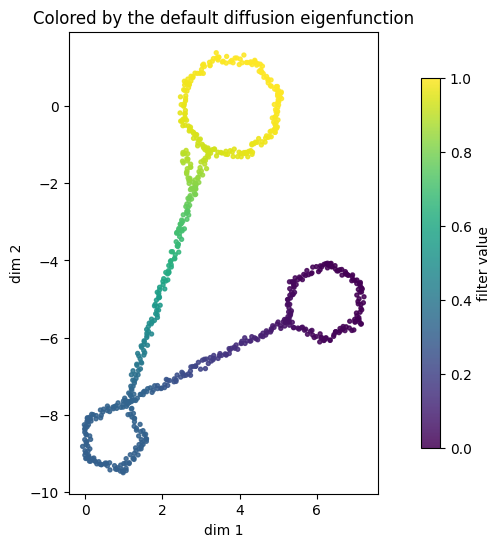

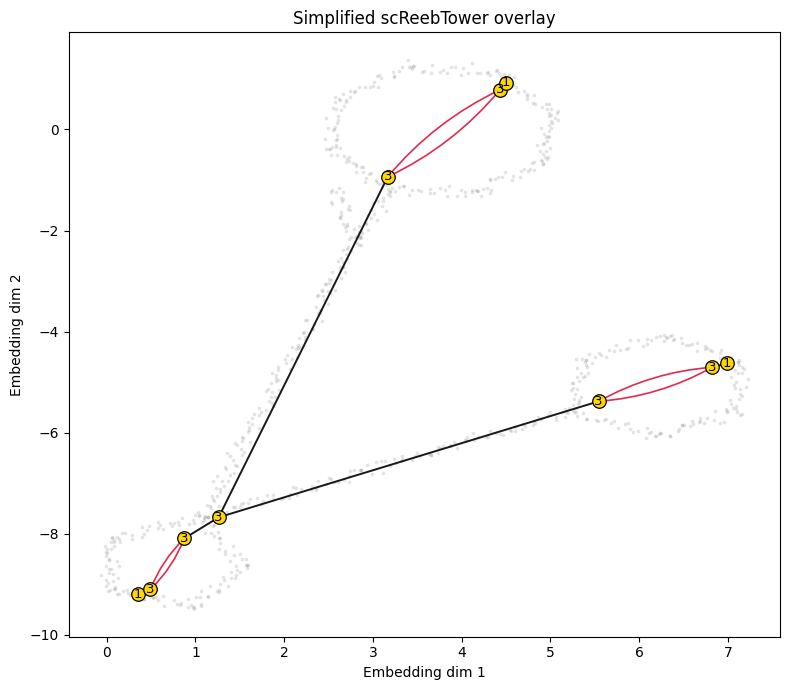

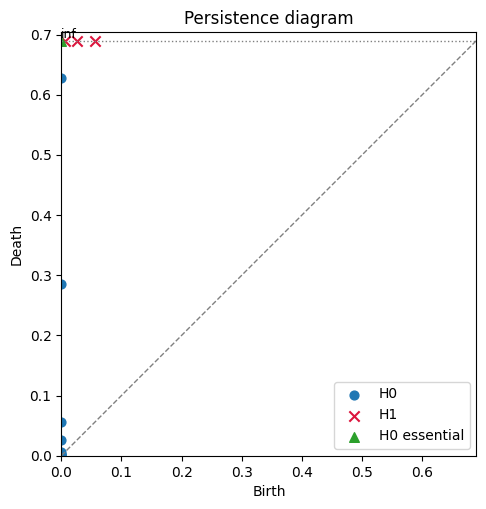

In [42]:
plot_filter_values(
    syn1['noisy_points'],
    syn1_result["intermediates"]["filter_values"],
    title="Colored by the default diffusion eigenfunction",
)
plot_overlay(syn1_result, syn1['noisy_points'], title="Simplified scReebTower overlay", label_degree=True)
plot_persistence_diagram(syn1_result["simplified"]["persistence"], title="Persistence diagram")

### Second (Harder) Point Cloud

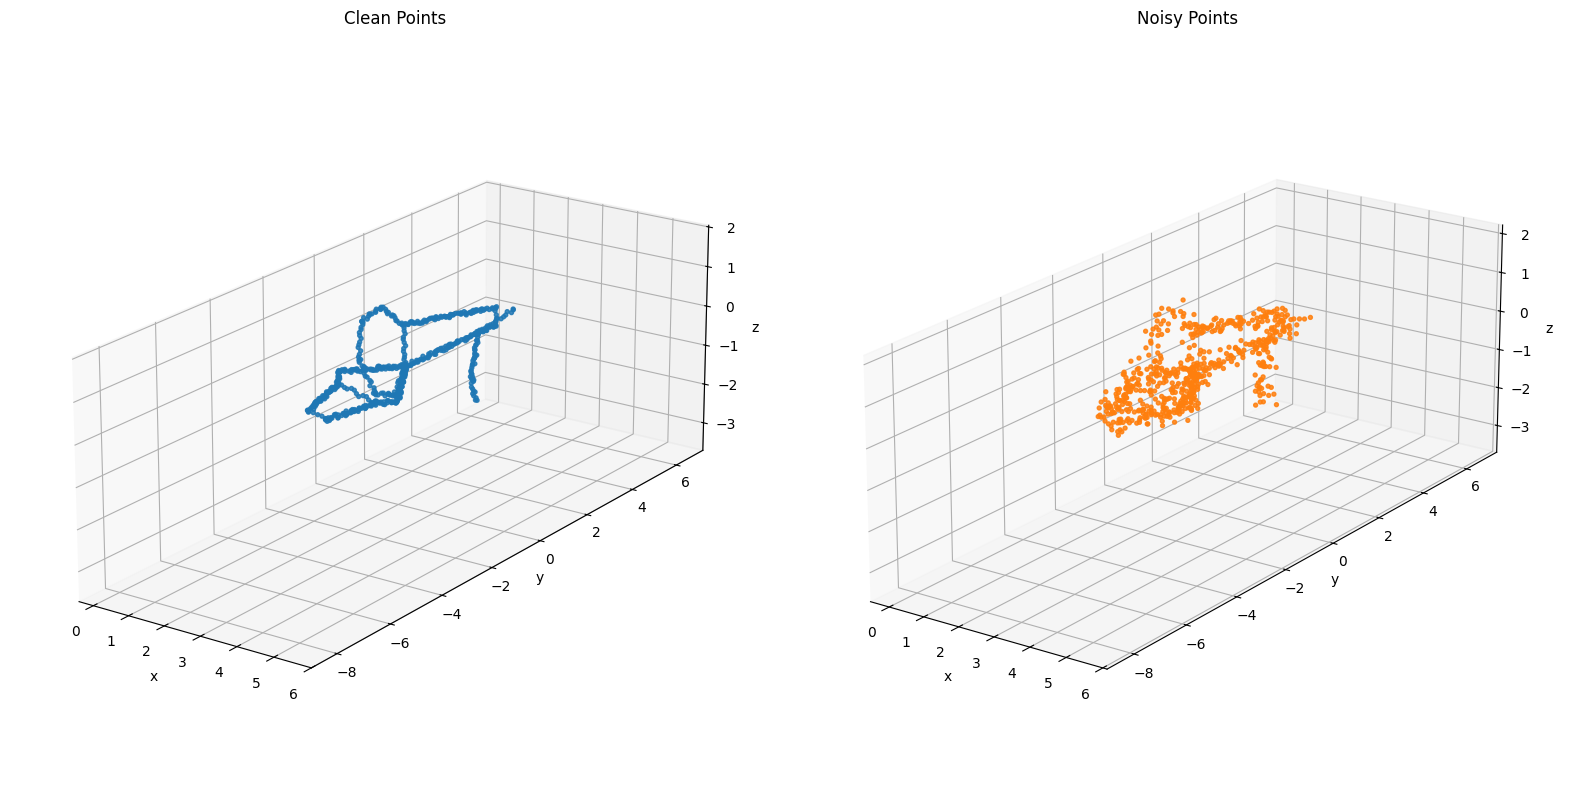

In [27]:
plot_clean_noisy(syn2)

In [28]:
syn2_results = scReebTower_with_plotting(
    syn2['noisy_points'],
    k=30,
    diffusion_eigen_index=1,
    return_point_assignment=True,
    return_edge_assignment=True,
    return_cellular_decomposition=True,
)
summarize_result(syn2_results, title="Synthetic point cloud")

Synthetic point cloud
---------------------
nodes: 6
edges: 7
beta1: 2
components: 1
H1 count: 2
selected diffusion eigenvalues: [0.99692655]


In [29]:
print_metadata(syn1_meta, title="Synthetic dataset metadata")

Synthetic dataset metadata
--------------------------
sample_id:              10
difficulty:             full
topology_class:         branchy_cycle
embedding_dimension:    3
num_components:         1
H1 cycles:              2
leaf_count:             17
num_nodes:              61
num_edges:              62
num_clean_points:       1553
tube_sampling_mode:     solid
noise_ratio:            0.0312
crowding_r:             0.0156
sampling_density:       22.30
feature_thickness:      0.6718


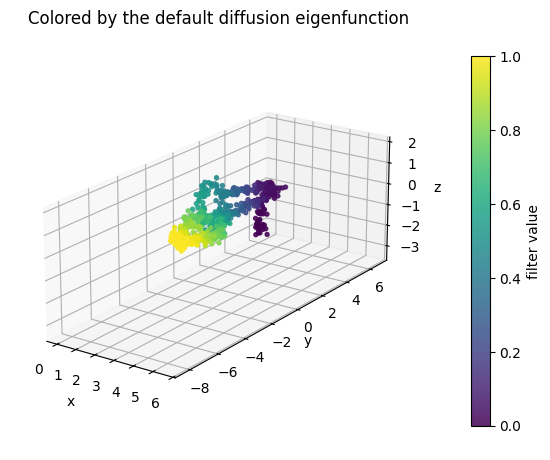

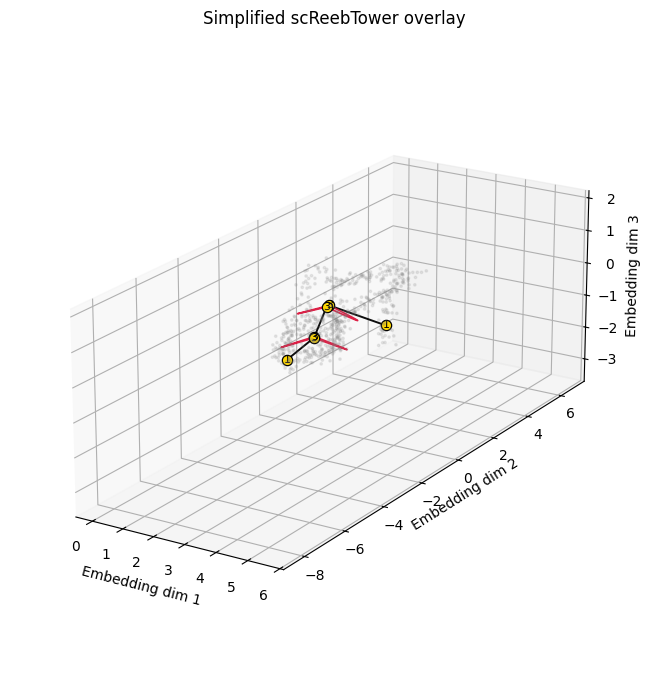

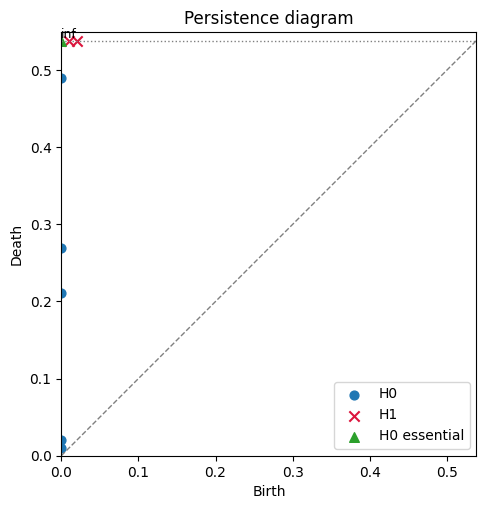

In [41]:
plot_filter_values(
    syn2['noisy_points'],
    syn2_results["intermediates"]["filter_values"],
    title="Colored by the default diffusion eigenfunction",
)
plot_overlay(syn2_results, syn2['noisy_points'], title="Simplified scReebTower overlay", label_degree=True)
plot_persistence_diagram(syn2_results["simplified"]["persistence"], title="Persistence diagram")

### Smoothing

#### Fixed Operator

$X_{smoothed} = P^t X$

In [16]:
syn2_result_fixed_operator = scReebTower_with_plotting(
    syn2['noisy_points'],
    k=30,
    diffusion_eigen_index=1,
    return_point_assignment=True,
    return_edge_assignment=True,
    return_cellular_decomposition=True,
    smoothing_mode = 'fixed_operator',
    t = 'auto'
)

summarize_result(syn2_result_fixed_operator, title="Synthetic point cloud with fixed-operator smoothing")

Synthetic point cloud with fixed-operator smoothing
---------------------------------------------------
nodes: 4
edges: 4
beta1: 1
components: 1
H1 count: 1
selected diffusion eigenvalues: [0.998863]


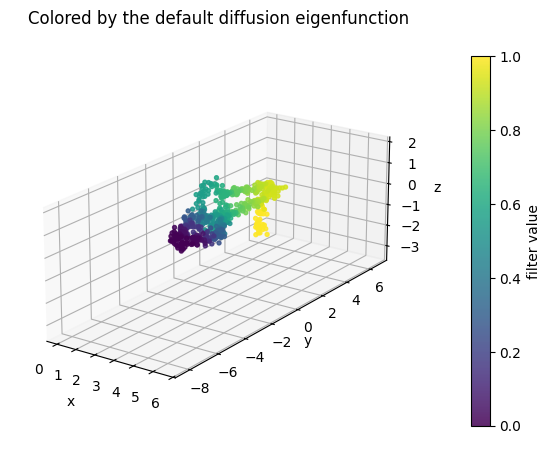

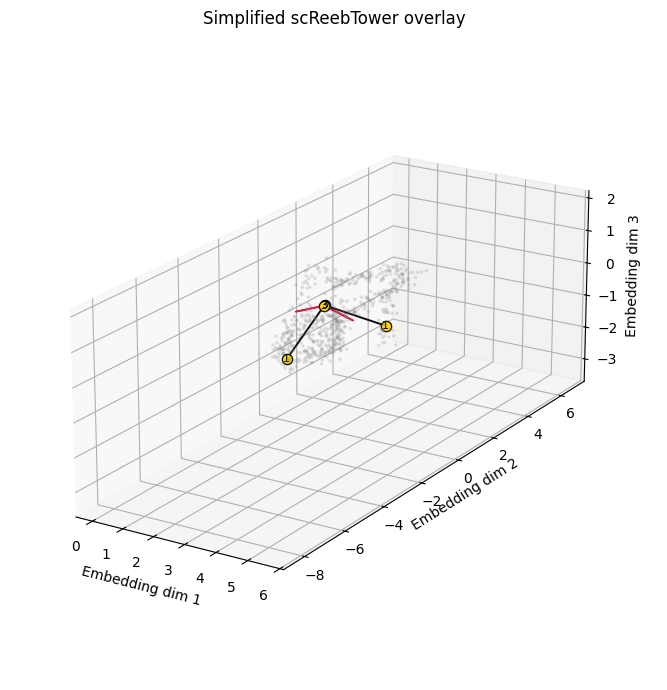

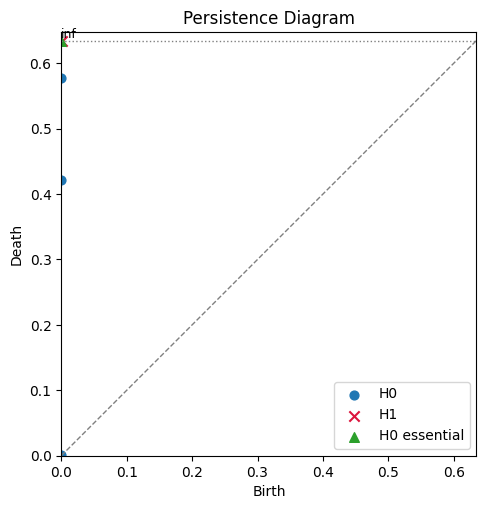

In [17]:
plot_filter_values(
    syn2['noisy_points'],
    syn2_result_fixed_operator["intermediates"]["filter_values"],
    title="Colored by the default diffusion eigenfunction",
)
plot_overlay(syn2_result_fixed_operator, syn2['noisy_points'], title="Simplified scReebTower overlay", label_degree=True)
plot_persistence_diagram(syn2_result_fixed_operator["simplified"]["persistence"], title="Persistence Diagram")

#### Condensation

$X^{(r+1)} = P_r^t X^{(r)}$

In [38]:
syn2_result_condensation = scReebTower_with_plotting(
    syn2['noisy_points'],
    k=30,
    diffusion_eigen_index=1,
    return_point_assignment=True,
    return_edge_assignment=True,
    return_cellular_decomposition=True,
    smoothing_mode = 'condensation',
    ell = 2,
    t = 2
)

summarize_result(syn2_result_condensation, title="Synthetic point cloud with condensation")

Synthetic point cloud with condensation
---------------------------------------
nodes: 6
edges: 7
beta1: 2
components: 1
H1 count: 2
selected diffusion eigenvalues: [0.99883133]


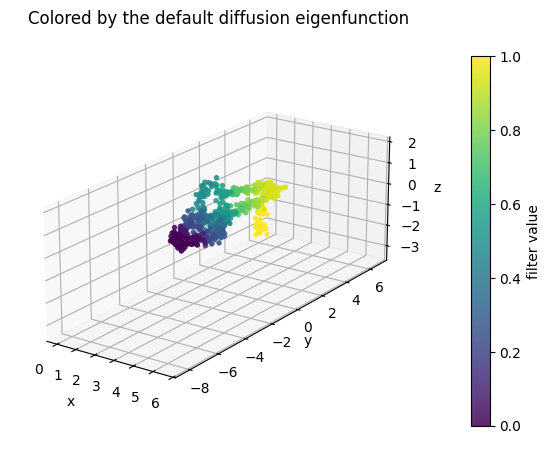

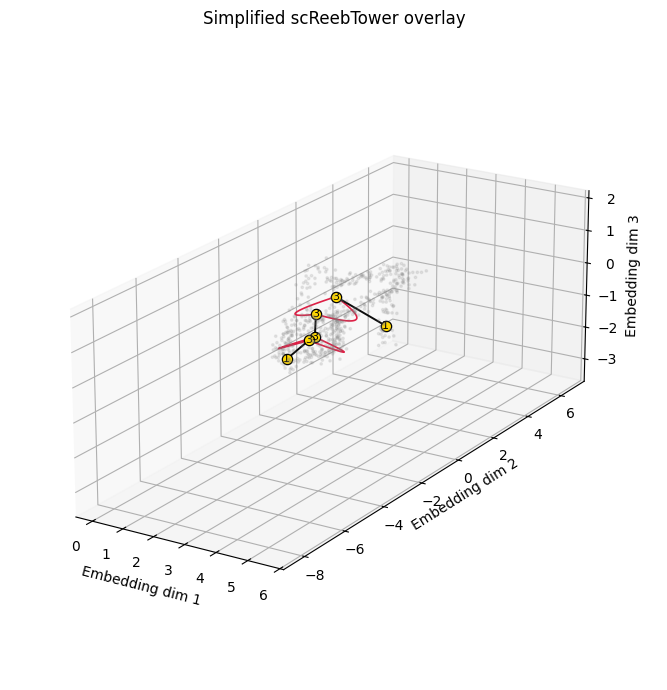

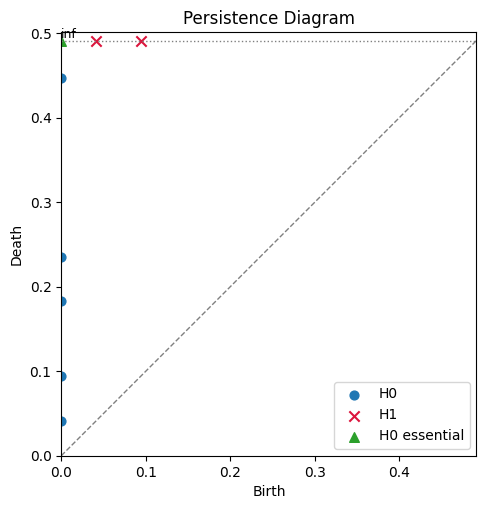

In [40]:
plot_filter_values(
    syn2['noisy_points'],
    syn2_result_condensation["intermediates"]["filter_values"],
    title="Colored by the default diffusion eigenfunction",
)
plot_overlay(syn2_result_condensation, syn2['noisy_points'], title="Simplified scReebTower overlay", label_degree=True)
plot_persistence_diagram(syn2_result_condensation["simplified"]["persistence"], title="Persistence Diagram")

## Single Cell RNA imports

In [11]:
sc1_raw =  ad.read_h5ad(hf_hub_download(repo_id="scShape-Benchmark/scShapeBench", repo_type="dataset", filename=f"data/scRNAseq/{sc1_ds}.h5ad"))
sc2_raw = ad.read_h5ad(hf_hub_download(repo_id="scShape-Benchmark/scShapeBench", repo_type="dataset", filename=f"data/scRNAseq/{sc2_ds}.h5ad"))

if "X_pca" in sc1_raw.obsm:
    sc1_X = sc1_raw.obsm["X_pca"]
else:
    sc1_X = PCA(n_components=50).fit_transform(sc1_raw.X)
if "X_pca" in sc2_raw.obsm:
    sc2_X = sc2_raw.obsm["X_pca"]
else:
    sc2_X = PCA(n_components=50).fit_transform(sc2_raw.X)

df = pd.read_parquet("hf://datasets/scShape-Benchmark/scShapeBench/labels/labels.parquet")

sc1_label = df[(df["dataset_id"] == sc1_ds) & (df["aggregation"] == "soft")]
sc2_label = df[(df["dataset_id"] == sc2_ds) & (df["aggregation"] == "soft")]

### Standard scReebTower

In [12]:
sc1_2d = project_pca_2d(sc1_X)
sc1_result = scReebTower_with_plotting(sc1_X, k=72)

# Choose any dimension reduction algorithm
sc1_phate = phate.PHATE(n_components=2, random_state=42, knn = 500,t = 12, decay = 60).fit_transform(sc1_X)

Calculating PHATE...
  Running PHATE on 8368 observations and 50 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculated KNN search in 0.67 seconds.
    Calculating affinities...
    Calculated affinities in 1.01 seconds.
  Calculated graph and diffusion operator in 2.14 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 7.75 seconds.
    Calculating KMeans...
    Calculated KMeans in 1.30 seconds.
  Calculated landmark operator in 9.07 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.12 seconds.
  Calculating metric MDS...
    SGD-MDS may not have converged: stress changed by 1.0% in final iterations. Consider increasing n_iter or adjusting learning_rate.
  Calculated metric MDS in 2.23 seconds.
Calculated PHATE in 16.30 seconds.


Torus with plotting and persistence outputs
-------------------------------------------
nodes: 12
edges: 15
beta1: 4
components: 1
H1 count: 4
selected diffusion eigenvalues: [0.99510608]


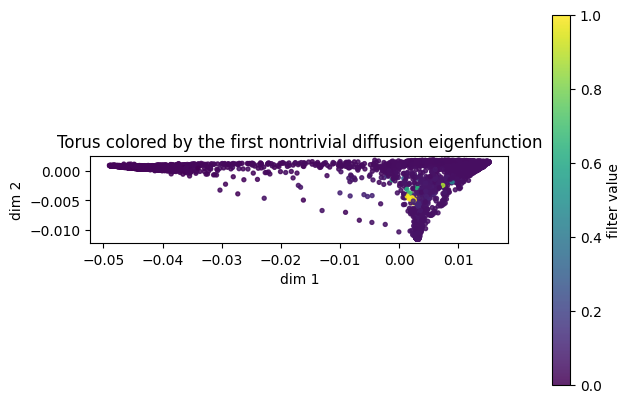

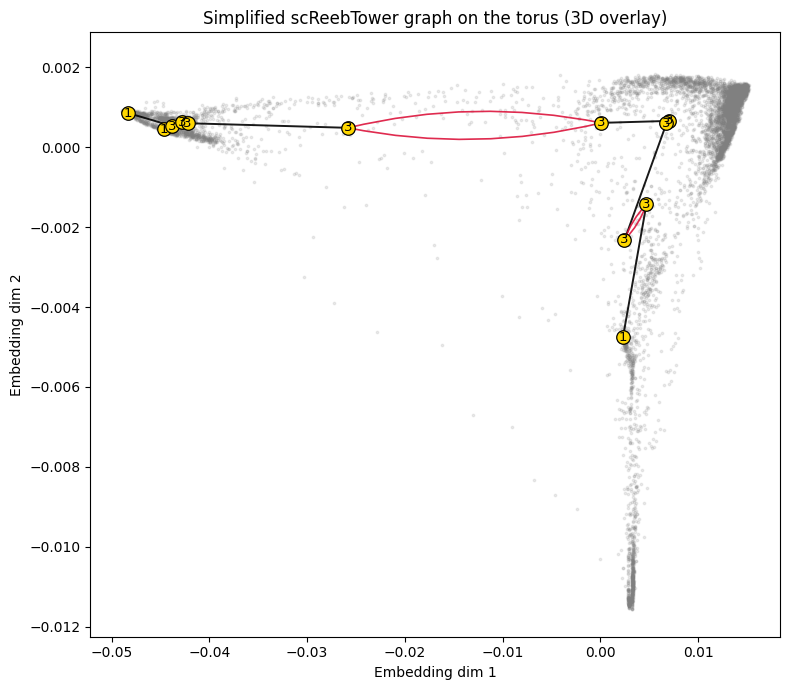

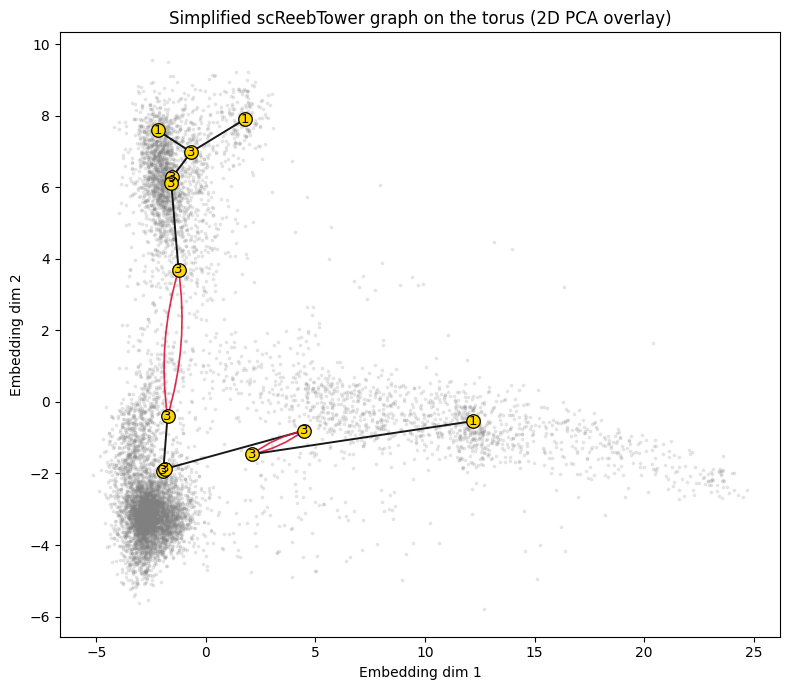

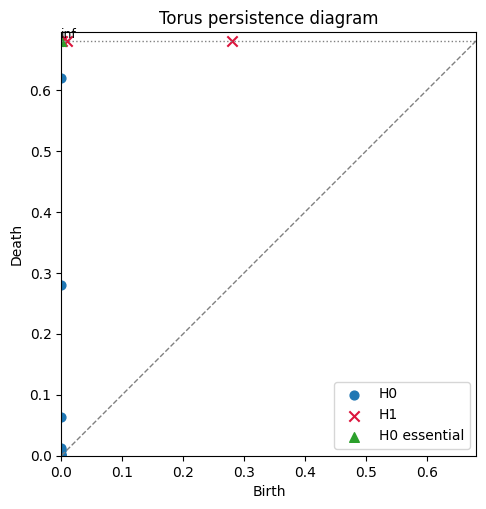

In [46]:
summarize_result(sc1_result, title="Torus with plotting and persistence outputs")

plot_filter_values(
    sc1_phate,
    sc1_result["intermediates"]["filter_values"],
    title="Torus colored by the first nontrivial diffusion eigenfunction",
)

plot_overlay(sc1_result, sc1_phate, title="Simplified scReebTower graph on the torus (3D overlay)")
plot_overlay(sc1_result, sc1_2d, title="Simplified scReebTower graph on the torus (2D PCA overlay)")
plot_persistence_diagram(sc1_result["simplified"]["persistence"], title="Torus persistence diagram")

### Second (Harder) Point Cloud

In [13]:
sc2_2d = project_pca_2d(sc2_X)
sc2_result = scReebTower_with_plotting(sc2_X,k=72)

In [14]:
# Choose any dimension reduction algorithm
sc2_phate = phate.PHATE(n_components=2, random_state=0, knn = 10, t=12, decay=60).fit_transform(sc2_X)

Calculating PHATE...
  Running PHATE on 21225 observations and 50 variables.
  Calculating graph and diffusion operator...
    Calculating KNN search...
    Calculated KNN search in 0.25 seconds.
    Calculating affinities...
    Calculated affinities in 0.30 seconds.
  Calculated graph and diffusion operator in 0.58 seconds.
  Calculating landmark operator...
    Calculating SVD...
    Calculated SVD in 0.88 seconds.
    Calculating KMeans...
    Calculated KMeans in 1.03 seconds.
  Calculated landmark operator in 1.92 seconds.
  Calculating diffusion potential...
  Calculated diffusion potential in 0.10 seconds.
  Calculating metric MDS...
  Calculated metric MDS in 2.25 seconds.
Calculated PHATE in 5.31 seconds.


SCD-0074 plotting and persistence outputs
-----------------------------------------
nodes: 108
edges: 165
beta1: 58
components: 1
H1 count: 58
selected diffusion eigenvalues: [0.99984794]


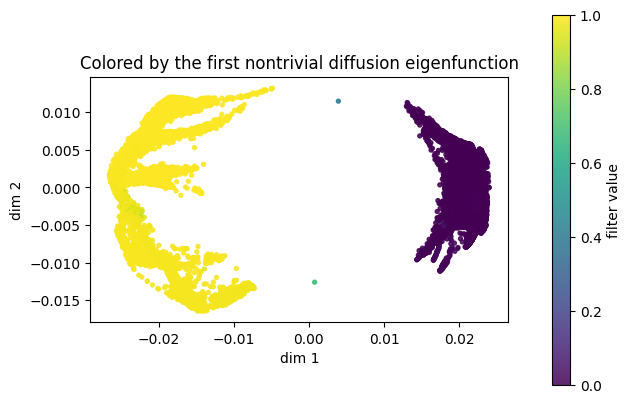

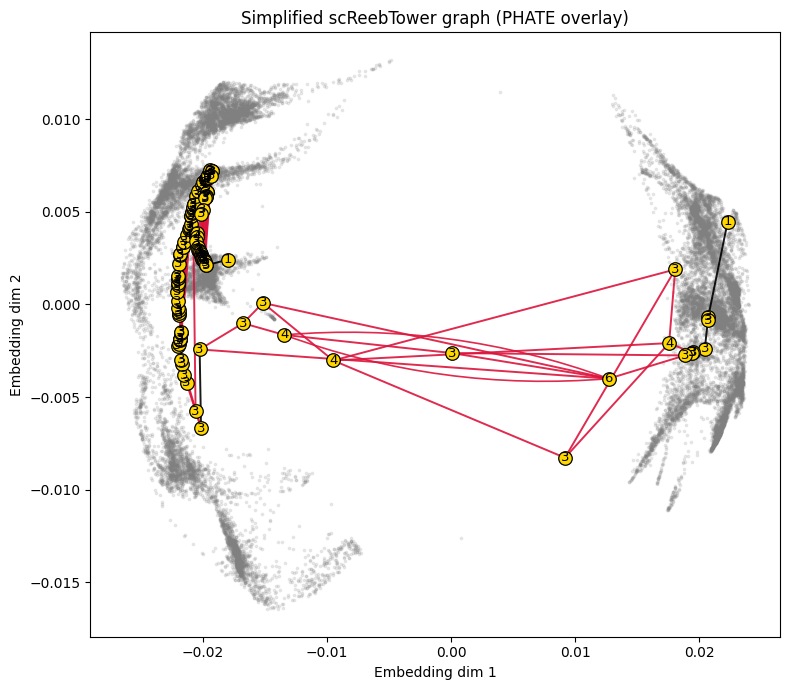

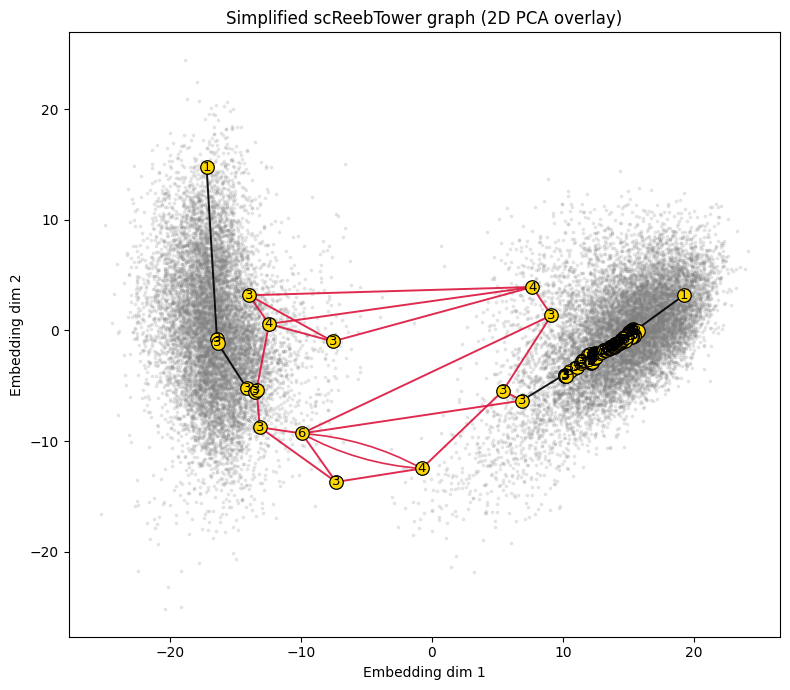

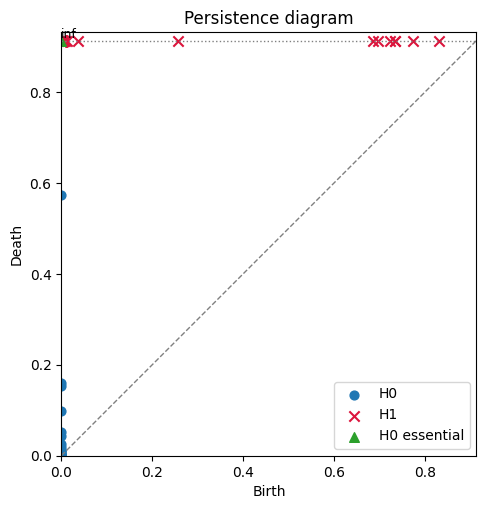

In [20]:
summarize_result(sc2_result, title=f"{sc2_ds} plotting and persistence outputs")

plot_filter_values(
    sc2_phate,
    sc2_result["intermediates"]["filter_values"],
    title="Colored by the first nontrivial diffusion eigenfunction",
)

plot_overlay(sc2_result, sc2_phate, title="Simplified scReebTower graph (PHATE overlay)")
plot_overlay(sc2_result, sc2_2d, title="Simplified scReebTower graph (2D PCA overlay)")
plot_persistence_diagram(sc2_result["simplified"]["persistence"], title="Persistence diagram")

### Smoothing
#### Fixed Operator

$X_{smoothed} = P^t X$

In [21]:
sc2_result_fixed_operator = scReebTower_with_plotting(
    sc2_X,
    k=72,
    smoothing_mode = 'fixed_operator',
    t = 'auto'
    )

SCD-0074 with plotting and persistence outputs
----------------------------------------------
nodes: 14
edges: 13
beta1: 0
components: 1
H1 count: 0
selected diffusion eigenvalues: [0.99999911]


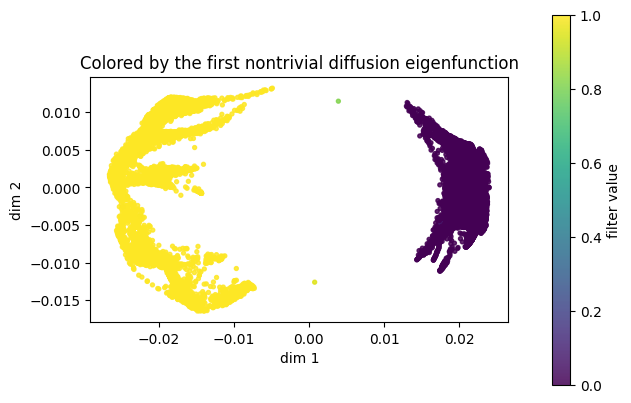

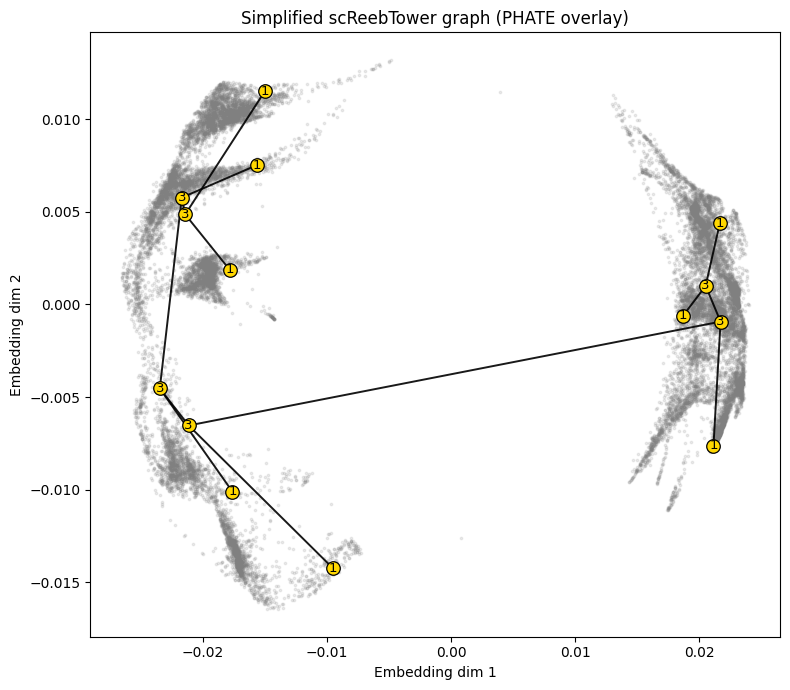

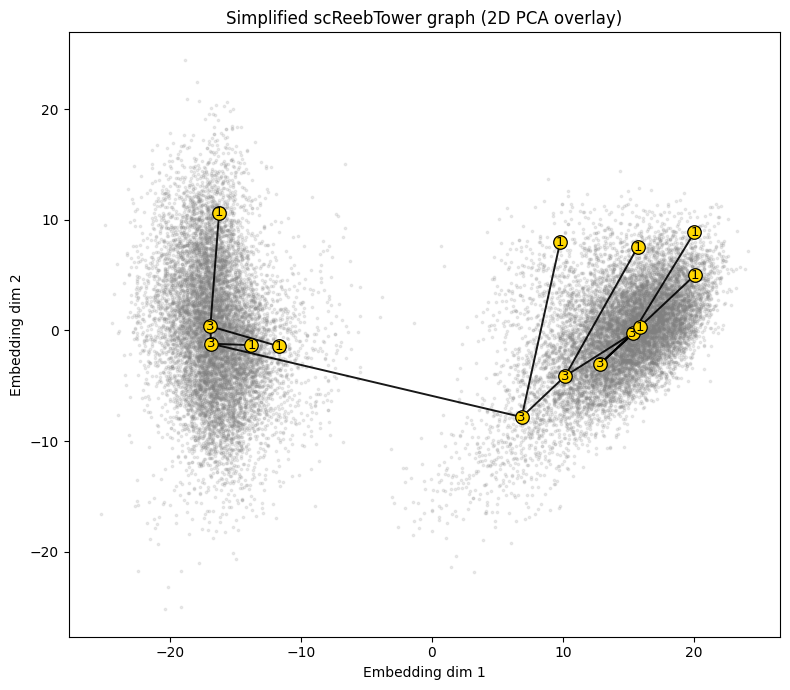

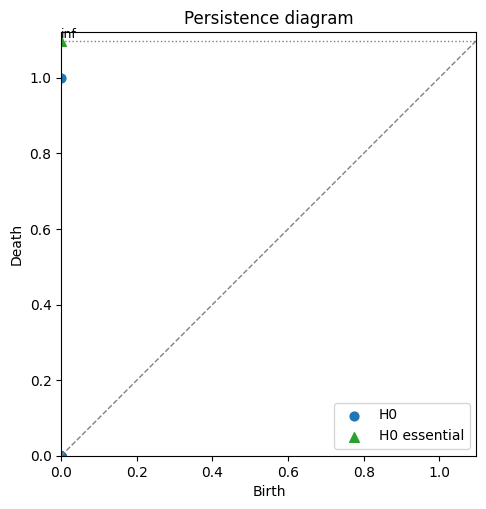

In [22]:
summarize_result(sc2_result_fixed_operator, title=f"{sc2_ds} with plotting and persistence outputs")

plot_filter_values(
    sc2_phate,
    sc2_result_fixed_operator["intermediates"]["filter_values"],
    title="Colored by the first nontrivial diffusion eigenfunction",
)

plot_overlay(sc2_result_fixed_operator, sc2_phate, title="Simplified scReebTower graph (PHATE overlay)")
plot_overlay(sc2_result_fixed_operator, sc2_2d, title="Simplified scReebTower graph (2D PCA overlay)")
plot_persistence_diagram(sc2_result_fixed_operator["simplified"]["persistence"], title="Persistence diagram")

#### Condensation

$X^{(r+1)} = P_r^t X^{(r)}$

In [20]:
sc2_result_condensation = scReebTower_with_plotting(
    sc2_X,
    k=72,
    smoothing_mode = 'condensation',
    t = 'auto',
    ell = 2
    )

Torus with plotting and persistence outputs
-------------------------------------------
nodes: 24
edges: 25
beta1: 3
components: 2
H1 count: 3
selected diffusion eigenvalues: [0.99984579 0.99967095]


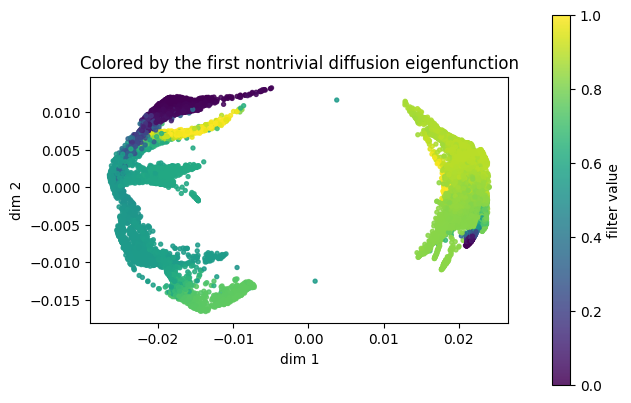

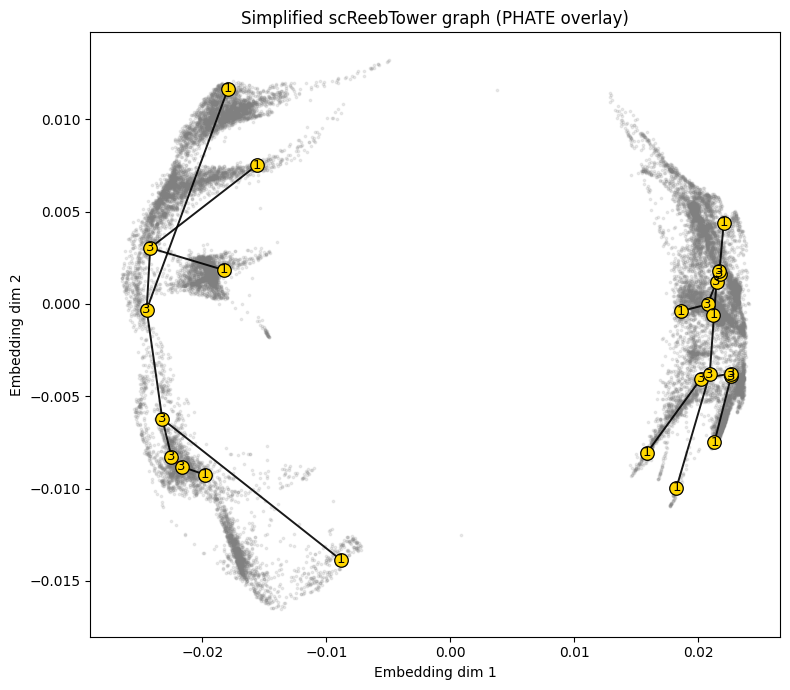

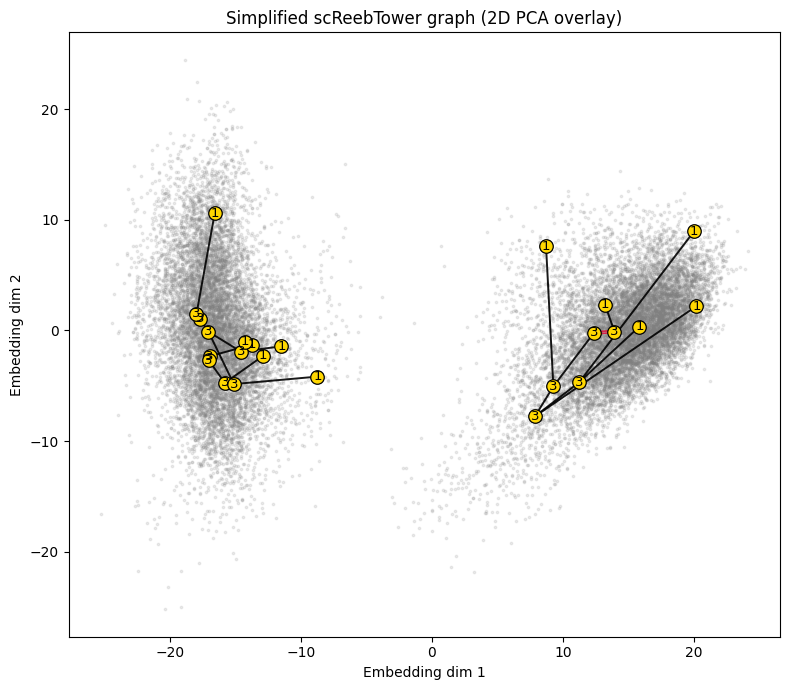

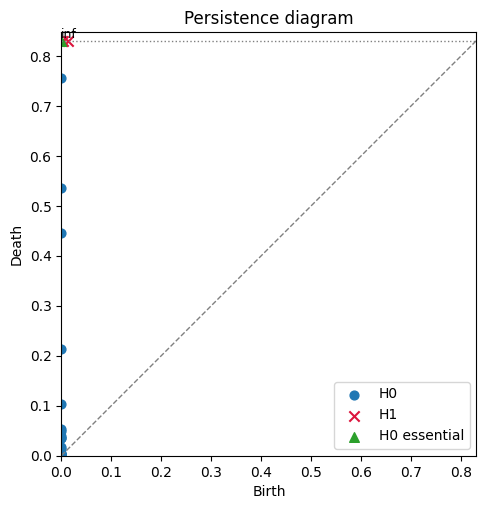

In [21]:
summarize_result(sc2_result_condensation, title="Torus with plotting and persistence outputs")

plot_filter_values(
    sc2_phate,
    sc2_result_condensation["intermediates"]["filter_values"],
    title="Colored by the first nontrivial diffusion eigenfunction",
)

plot_overlay(sc2_result_condensation, sc2_phate, title="Simplified scReebTower graph (PHATE overlay)")
plot_overlay(sc2_result_condensation, sc2_2d, title="Simplified scReebTower graph (2D PCA overlay)")
plot_persistence_diagram(sc2_result_condensation["simplified"]["persistence"], title="Persistence diagram")